# 05 — Currency-risk pricing for USD and EUR investors

Add explicit currency-covariance premia to the three equity pricing equations. Use two independent
FX factors in each investor currency, and jointly estimate equity means, FX forecasting equations
and the five-variable covariance process. Compare zero versus nonzero currency prices within the
**same system**, under both scalar and diagonal BEKK covariance models.

Run **Run All** in the existing Miniconda **base** kernel, after `dataset.ipynb`. No downloads or
API keys are used. The fixed **2000-01 to 2026-09** sample stays intact: lagged FX observations
come from the already frozen 1999 ECB source. Settings are in the first cell; a final summary,
price tests, diagnostics and Hungarian premium decompositions are saved locally.

In [1]:
# Adjustable settings. Never fetch data or change the frozen snapshot in this notebook.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None
ANALYSIS_END = None
FX_VAR_LAGS = 6  # Exploratory mean specification; change to compare a separate run.
COVARIANCE_MODELS = ["scalar", "diagonal"]
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.75)]  # alpha, beta
MAX_ITER = 1600
TEST_LAGS = 12
REUSE_FITS = True  # False forces re-estimation; model code and settings enter the cache key.
MODEL_VERSION = "currency_equity_pricing_v1"

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import norm, chi2
from packaging.version import Version
sm_version = importlib.metadata.version("statsmodels")
if Version(sm_version) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0, then Restart Kernel and Run All.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != sm_version:
    raise RuntimeError("statsmodels was updated. Restart Kernel and Run All to discard old imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import display, Markdown

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
print("Python:", sys.executable)
print("Packages:", versions)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
source = ROOT / SNAPSHOT
manifest = json.loads((source / "manifest.json").read_text())
raw = (source / "dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("The frozen dataset is not sealed or its checksum differs.")
data = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
data.index = pd.PeriodIndex(data.index, freq="M", name="month")
if not data.index.equals(pd.period_range(data.index[0], data.index[-1], freq="M")):
    raise ValueError("Missing or duplicate months.")
data = data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if len(data) < max(120, 5 * TEST_LAGS) or not 2 <= TEST_LAGS <= 24:
    raise ValueError("Use at least 120 months and TEST_LAGS from 2 to 24 for this initial fit.")

if not isinstance(FX_VAR_LAGS, int) or not 0 <= FX_VAR_LAGS <= 12:
    raise ValueError("FX_VAR_LAGS must be an integer from 0 to 12.")
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS)) != len(COVARIANCE_MODELS) or any(
        c not in ["scalar", "diagonal"] for c in COVARIANCE_MODELS):
    raise ValueError("Choose scalar, diagonal, or both covariance models without duplicates.")
if any(a <= 0 or b <= 0 or a+b >= 1 for a,b in START_DYNAMICS):
    raise ValueError("Starting alpha/beta must be positive and sum to less than one.")
# Estimate scalar first if both are requested, to initialise the nested diagonal model.
COVARIANCE_MODELS = [c for c in ["scalar", "diagonal"] if c in COVARIANCE_MODELS]
ASSETS = ["World", "US", "Hungary", "HUF FX", "Other FX"]
FX_NAMES = {"USD": ["HUF", "EUR"], "EUR": ["HUF", "USD"]}
fx_raw = (source / "raw" / "ecb_fx.csv").read_bytes()
fx_source_sha256 = hashlib.sha256(fx_raw).hexdigest()
if fx_source_sha256 != manifest["sources"]["ecb_fx.csv"]["sha256"]:
    raise ValueError("Frozen ECB source checksum differs.")
ecb = pd.read_csv(BytesIO(fx_raw), usecols=["TIME_PERIOD", "CURRENCY", "OBS_VALUE"], float_precision="round_trip")
ecb["TIME_PERIOD"] = pd.to_datetime(ecb["TIME_PERIOD"])
ecb["OBS_VALUE"] = pd.to_numeric(ecb["OBS_VALUE"], errors="raise")
ecb = ecb.pivot(index="TIME_PERIOD", columns="CURRENCY", values="OBS_VALUE").sort_index()
ecb = ecb.groupby(ecb.index.to_period("M")).last()
fx_usd = pd.DataFrame({"HUF": -np.log(ecb["HUF"] / ecb["USD"]).diff(),
                       "EUR": np.log(ecb["USD"]).diff()}) * 100
fx_eur = pd.DataFrame({"HUF": fx_usd["HUF"] - fx_usd["EUR"], "USD": -fx_usd["EUR"]})
np.testing.assert_allclose(fx_usd.loc[data.index].to_numpy(),
                          data[["fx_huf_usd", "fx_eur_usd"]].to_numpy()*100, atol=1e-11, rtol=0)
np.testing.assert_allclose(fx_eur.loc[data.index, "HUF"], data["fx_huf_eur"]*100, atol=1e-11, rtol=0)
samples, designs, scales_by_currency = {}, {}, {}
for currency, fx in [("USD", fx_usd), ("EUR", fx_eur)]:
    equities = data[[f"rx_{a}_{currency.lower()}" for a in ["world", "us", "hu"]]].to_numpy()*100
    y = np.c_[equities, fx.loc[data.index].to_numpy()]
    scales = y.std(axis=0, ddof=1)
    lagged = [(fx/scales[3:]).shift(lag).loc[data.index].to_numpy() for lag in range(1, FX_VAR_LAGS+1)]
    x = np.c_[np.ones(len(data)), np.concatenate(lagged, axis=1)] if lagged else np.ones((len(data),1))
    if not np.isfinite(y).all() or not np.isfinite(x).all() or not (scales>0).all():
        raise ValueError("Missing FX history or non-finite data. Reduce FX_VAR_LAGS or move ANALYSIS_START later.")
    if np.linalg.matrix_rank(x) != x.shape[1]:
        raise ValueError("FX mean design is rank deficient.")
    samples[currency], designs[currency], scales_by_currency[currency] = y, x, scales
# Check the observed USD-to-EUR transformation, including the two different cash proxies.
transform = np.eye(5)
transform[:3,4], transform[3,4], transform[4,4] = -1., -1., -1.
converted = samples["USD"] @ transform.T
converted[:,:3] += ((data["rf_usd"]-data["rf_eur_proxy"])*100).to_numpy()[:,None]
np.testing.assert_allclose(converted, samples["EUR"], atol=1e-10, rtol=0)
OUT = ROOT / "output" / "05_currency_risk" / source.parent.name / f"{data.index[0]}_{data.index[-1]}" / f"var{FX_VAR_LAGS}"
OUT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({"first":[str(data.index[0])], "last":[str(data.index[-1])], "months":[len(data)],
                      "equities":[3], "independent_FX_factors":[2], "FX_VAR_lags":[FX_VAR_LAGS],
                      "unit":["monthly log percentage points"]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,equities,independent_FX_factors,FX_VAR_lags,unit
0,2000-01,2026-09,321,3,2,6,monthly log percentage points


## 1. Currency definitions and the pricing equation

All FX factors are **foreign-currency appreciation against the investor currency**, in monthly log
percentage points. For $S^{HUF/USD}$ = HUF per USD and $S^{USD/EUR}$ = USD per EUR:

| Investor | HUF factor $f_H$ | Other factor $f_O$ |
|---|---|---|
| USD | $-100\Delta\log S^{HUF/USD}$ | $+100\Delta\log S^{USD/EUR}$ (EUR appreciation) |
| EUR | $-100\Delta\log S^{HUF/EUR}$ | $-100\Delta\log S^{USD/EUR}$ (USD appreciation) |

There are only **two independent** bilateral factors: $f_H^{EUR}=f_H^{USD}-f_{EUR}^{USD}$ and
$f_{USD}^{EUR}=-f_{EUR}^{USD}$. Including all three bilateral rates would make the system singular.
The extra factor covers EUR/USD risk, including the US equity portfolio's FX exposure in EUR.
These factors do not cover every currency in the developed-world portfolio.

Following the equity restriction in [Antell and Vaihekoski, equations (5)–(6)](https://www.researchgate.net/publication/222411851_International_asset_pricing_models_and_currency_risk_Evidence_from_Finland_1970-2004),
(equation numbers refer to the supplied April 2005 draft), for $i\in\{W,US,HU\}$ we estimate

$$\boxed{\mu_{i,t}=\lambda_W H_{iW,t}+\lambda_H H_{iH,t}+\lambda_O H_{iO,t}
+\mathbf{1}_{i=US}\lambda_{US}H_{US,US,t}
+\mathbf{1}_{i=HU}\lambda_{HU}H_{HU,HU,t}.}$$

Here $H_t$ is the conditional covariance of the **joint innovations** in
$(r_W^e,r_{US}^e,r_{HU}^e,f_H,f_O)'$. All five risk prices are constant and unrestricted in sign.
`no_fx` fixes $\lambda_H=\lambda_O=0$; `with_fx` estimates both, with local prices free in both models.
A nonzero covariance alone is exposure, not evidence that FX is priced. Reversing an FX factor's sign
reverses its price; the product contributing to the equity premium is unchanged.

## 2. Forecast spot FX separately

For the two spot-change factors, estimate an unrestricted VAR with an intercept:

$$f_t=c+\sum_{\ell=1}^{p}\Phi_\ell f_{t-\ell}+u_t,\qquad p=\texttt{FX\_VAR\_LAGS}.$$

This is an explicit adaptation: we test the paper's **equity-pricing** restriction, while leaving spot-FX
means as nuisance forecasting equations. We do **not** impose the paper's additional currency mean
restriction (7), or treat spot changes as currency-deposit excess returns. No HUF cash or forward
series is needed for this version. Every VAR coefficient is estimated jointly and enters uncertainty.

The default six lags are an **exploratory response to the earlier FX serial-dependence screen**.
Use the same lag choice in both perspectives and nested models. Price p-values are conditional on
this mean specification; there is no adjustment for choosing it after inspecting this sample.
Changing the lag setting writes a separate output folder. Lagged values come from frozen 1999
observations, preserving all 321 working months. Only past observations enter the mean design.

For covariance, keep the positive-definite BEKK recursion used in notebook 04:

$$H_t=CC'+A\varepsilon_{t-1}\varepsilon_{t-1}'A'+BH_{t-1}B',\quad
A=\operatorname{diag}(\sqrt{\alpha_i}),\quad B=\operatorname{diag}(\sqrt{\beta_i}),$$

with $\alpha_i,\beta_i>0$, $\alpha_i+\beta_i<1$, and stationary initial innovation covariance
$H_{0,ij}=(CC')_{ij}/(1-\sqrt{\alpha_i\alpha_j}-\sqrt{\beta_i\beta_j})$.
The scalar model shares both coefficients across all five series; the diagonal model estimates each
pair separately. The intercept $CC'$ is free in both. See [Engle and Kroner (1995)](https://doi.org/10.1017/S0266466600009063).

In [2]:
PRICE_SCALE = 0.01
N = 5
TRI = np.tril_indices(N)

def layout(x, with_fx, covariance_model):
    k = 5 if with_fx else 3
    g = 2 * x.shape[1]
    dynamics = N * 2 if covariance_model == 'diagonal' else 2
    return k, g, dynamics

def unpack(theta, scales, x, with_fx, covariance_model):
    k, g, dynamics = layout(x, with_fx, covariance_model)
    q = len(theta)
    prices, dp = np.zeros(5), np.zeros((q, 5))
    prices[:k] = PRICE_SCALE * theta[:k]
    dp[np.arange(k), np.arange(k)] = PRICE_SCALE
    gamma = theta[k:k+g].reshape(2, x.shape[1])
    C, dC = np.zeros((N, N)), np.zeros((q, N, N))
    for offset, (i, j) in enumerate(zip(*TRI)):
        index = k + g + offset
        value = np.exp(theta[index]) if i == j else theta[index]
        C[i, j] = scales[i] * value
        dC[index, i, j] = scales[i] * (value if i == j else 1.0)
    intercept = C @ C.T
    dintercept = dC @ C.T + C @ dC.transpose(0, 2, 1)
    weights = softmax(np.c_[np.zeros(dynamics // 2), theta[-dynamics:].reshape(-1, 2)], axis=1)
    alpha, beta = np.broadcast_to(weights[:, 1], N), np.broadcast_to(weights[:, 2], N)
    da, db = np.zeros((q, N)), np.zeros((q, N))
    for i in range(N):
        offset = i if covariance_model == 'diagonal' else 0
        u, v = q - dynamics + 2 * offset, q - dynamics + 2 * offset + 1
        da[u, i], da[v, i] = alpha[i] * (1-alpha[i]), -alpha[i]*beta[i]
        db[u, i], db[v, i] = -alpha[i]*beta[i], beta[i]*(1-beta[i])
    a, b = np.sqrt(alpha), np.sqrt(beta)
    da, db = da / (2*a), db / (2*b)
    aa, bb = np.outer(a, a), np.outer(b, b)
    daa = da[:, :, None]*a[None, None, :] + a[None, :, None]*da[:, None, :]
    dbb = db[:, :, None]*b[None, None, :] + b[None, :, None]*db[:, None, :]
    denominator = 1-aa-bb
    target = intercept / denominator
    dtarget = dintercept / denominator + intercept*(daa+dbb)/denominator**2
    return prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta

## 3. Joint Gaussian QML

Minimise $T^{-1}\sum_t\tfrac12[5\log(2\pi)+\log|H_t|+\varepsilon_t'H_t^{-1}\varepsilon_t]$.
Analytic derivatives include the mean and covariance recursion and the parameter-dependent $H_0$.
Scaling the VAR regressors/coefficients only improves numerical conditioning; it changes no fitted
mean equation. We retain the price scaling convention from the earlier notebooks.

In [3]:
def filter_model(theta, y, x, scales, with_fx, covariance_model):
    prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta = unpack(theta, scales, x, with_fx, covariance_model)
    H, dH = target.copy(), dtarget.copy()
    n, q = len(y), len(theta)
    k, g, _ = layout(x, with_fx, covariance_model)
    losses, scores = np.empty(n), np.empty((n, q))
    covariances, means, residuals = np.empty((n, N, N)), np.empty_like(y), np.empty_like(y)
    for t in range(n):
        if not np.isfinite(H).all() or np.max(np.diag(H)) > 1e8:
            raise FloatingPointError('Unstable covariance recursion')
        chol, inverse = np.linalg.cholesky(H), np.linalg.inv(H)
        mu, dmu = np.zeros(N), np.zeros((q, N))
        for price, factor in [(0, 0), (3, 3), (4, 4)]:
            mu[:3] += prices[price] * H[:3, factor]
            dmu[:, :3] += prices[price] * dH[:, :3, factor] + dp[:, price, None] * H[None, :3, factor]
        for asset in (1, 2):
            mu[asset] += prices[asset] * H[asset, asset]
            dmu[:, asset] += prices[asset]*dH[:, asset, asset] + dp[:, asset]*H[asset, asset]
        mu[3:] = scales[3:] * (gamma @ x[t])
        for j in range(2):
            start = k + j*x.shape[1]
            dmu[start:start+x.shape[1], 3+j] = scales[3+j]*x[t]
        error, de = y[t]-mu, -dmu
        v = inverse @ error
        losses[t] = .5*(N*np.log(2*np.pi)+2*np.log(np.diag(chol)).sum()+error@v)
        scores[t] = .5*np.einsum('ij,kij->k', inverse-np.outer(v,v), dH) + de@v
        covariances[t], means[t], residuals[t] = H, mu, error
        shock = np.outer(error, error)
        dshock = de[:, :, None]*error[None, None, :] + error[None, :, None]*de[:, None, :]
        dH = dintercept + daa*shock + aa*dshock + dbb*H + bb*dH
        H = intercept + aa*shock + bb*H
    return {'losses':losses, 'scores':scores, 'H':covariances, 'mu':means, 'errors':residuals,
            'prices':prices, 'gamma':gamma, 'intercept':intercept, 'target':target, 'alpha':alpha, 'beta':beta}

def objective(theta, y, x, scales, with_fx, covariance_model):
    try:
        with np.errstate(over='raise', invalid='raise', divide='raise'):
            f = filter_model(theta, y, x, scales, with_fx, covariance_model)
        if not np.isfinite(f['losses']).all() or not np.isfinite(f['scores']).all():
            raise FloatingPointError('Non-finite likelihood or gradient')
        return f['losses'].mean(), f['scores'].mean(axis=0)
    except (FloatingPointError, np.linalg.LinAlgError):
        return 1e8 + theta@theta, 2*theta

In [4]:
def initial_theta(y, x, scales, with_fx, covariance_model, alpha=.05, beta=.90):
    k, g, dynamics = layout(x, with_fx, covariance_model)
    gamma = np.linalg.lstsq(x, y[:, 3:]/scales[3:], rcond=None)[0].T
    centred = y.copy()
    centred[:, 3:] -= (x @ gamma.T)*scales[3:]
    covariance = np.cov(centred, rowvar=False)
    remaining = 1-alpha-beta
    C = np.linalg.cholesky(remaining*covariance/np.outer(scales,scales))
    chol = [np.log(C[i,j]) if i==j else C[i,j] for i,j in zip(*TRI)]
    world = y[:,0].mean()/covariance[0,0]
    prices = [world] + [(y[:,i].mean()-world*covariance[i,0])/covariance[i,i] for i in (1,2)]
    if with_fx: prices += [0.,0.]
    return np.r_[np.asarray(prices)/PRICE_SCALE, gamma.ravel(), chol,
                 np.tile([np.log(alpha/remaining),np.log(beta/remaining)], dynamics//2)]

def add_fx_prices(theta):
    return np.r_[theta[:3], 0., 0., theta[3:]]

def scalar_to_diagonal(theta):
    return np.r_[theta[:-2], np.tile(theta[-2:], N)]

def parameter_bounds(x, with_fx, covariance_model):
    k,g,dynamics = layout(x, with_fx, covariance_model)
    cov_bounds = [(-8.,3.) if i==j else (-4.,4.) for i,j in zip(*TRI)]
    return [(-100.,100.)]*k + [(-3.,3.)]*g + cov_bounds + [(-10.,10.)]*dynamics

def fit_starts(y, x, scales, with_fx, covariance_model, starts, maxiter=1600):
    bounds = np.asarray(parameter_bounds(x, with_fx, covariance_model))
    args = (y, x, scales, with_fx, covariance_model)
    runs, solutions = [], []
    for i, start in enumerate(starts, 1):
        # Full BFGS handles the weak price/covariance directions better than limited memory alone.
        coarse = minimize(objective, start, args=args, method='BFGS', jac=True,
                          options={'maxiter':maxiter, 'gtol':1e-6})
        # Restore numerical bounds after the exploratory BFGS step, then verify constrained convergence.
        projected = np.clip(coarse.x, bounds[:,0], bounds[:,1])
        result = minimize(objective, projected, args=args, method='L-BFGS-B', jac=True, bounds=bounds,
                          options={'maxiter':maxiter, 'ftol':1e-13, 'gtol':1e-7, 'maxls':50, 'maxcor':50})
        gradient = float(np.max(np.abs(result.jac)))
        print(f'  start {i}: success={result.success}, NLL={result.fun:.9f}, gradient={gradient:.2e}, '
              f'iterations={coarse.nit}+{result.nit}', flush=True)
        runs.append({'start':i, 'success':bool(result.success), 'mean_nll':float(result.fun),
                     'max_abs_gradient':gradient, 'iterations':int(coarse.nit+result.nit),
                     'BFGS_success':bool(coarse.success), 'polish_iterations':int(result.nit),
                     'message':str(result.message)})
        solutions.append(result)
    valid = [r for r in solutions if r.success and np.isfinite(r.fun) and r.fun<1e7
             and np.max(np.abs(r.jac))<1e-4]
    if not valid:
        raise RuntimeError('No converged fit with a small gradient; inspect starts and MAX_ITER.')
    best = min(valid, key=lambda r:r.fun)
    lower = [r for r in solutions if np.isfinite(r.fun) and r.fun<best.fun-1e-7]
    if lower:
        raise RuntimeError('A lower nonconverged candidate exists. Increase MAX_ITER before inference.')
    return best, runs

def numerical_gradient(function, theta, step=1e-5):
    result=np.empty_like(theta)
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j])); plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[j]=(function(plus)-function(minus))/(2*delta)
    return result

def loss_hessian(theta, y, x, scales, with_fx, covariance_model, step=1e-4):
    result=np.empty((len(theta),len(theta)))
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j]));plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[:,j]=(objective(plus,y,x,scales,with_fx,covariance_model)[1]-objective(minus,y,x,scales,with_fx,covariance_model)[1])/(2*delta)
    return (result+result.T)/2

def var_radius(gamma):
    lags=(gamma.shape[1]-1)//2
    if not lags: return 0.
    top=np.concatenate([gamma[:,1+2*j:3+2*j] for j in range(lags)],axis=1)
    companion=np.r_[top,np.c_[np.eye(2*(lags-1)),np.zeros((2*(lags-1),2))]]
    return float(np.max(np.abs(np.linalg.eigvals(companion))))


## 4. Check gradients and nested restrictions before fitting

Check both covariance models and both price restrictions. The nonzero-price checks use unequal
market dynamics in the diagonal model. Adding zero FX prices must reproduce every loss exactly;
repeating scalar dynamics must reproduce the complete covariance path under diagonal BEKK.

In [5]:
checks=[]
for currency,y in samples.items():
    x,scales=designs[currency],scales_by_currency[currency]
    for covariance_model in COVARIANCE_MODELS:
        for with_fx in [False,True]:
            theta=initial_theta(y,x,scales,with_fx,covariance_model)
            if with_fx: theta[3:5]=[0.3,-0.2]
            if covariance_model=="diagonal": theta[-10:]+=np.linspace(-0.15,0.15,10)
            analytic=objective(theta,y[:40],x[:40],scales,with_fx,covariance_model)[1]
            numeric=numerical_gradient(lambda v: objective(v,y[:40],x[:40],scales,with_fx,covariance_model)[0],theta)
            np.testing.assert_allclose(analytic,numeric,rtol=3e-5,atol=3e-6)
            checks.append({"perspective":currency,"covariance_model":covariance_model,
                           "with_fx":with_fx,"max_gradient_error":np.max(np.abs(analytic-numeric))})
    theta=initial_theta(y,x,scales,False,"scalar")
    original=filter_model(theta,y,x,scales,False,"scalar")
    nested=filter_model(add_fx_prices(theta),y,x,scales,True,"scalar")
    diagonal=filter_model(scalar_to_diagonal(theta),y,x,scales,False,"diagonal")
    np.testing.assert_allclose(original["losses"],nested["losses"],atol=1e-12,rtol=0)
    np.testing.assert_allclose(original["H"],diagonal["H"],atol=1e-12,rtol=0)
display(pd.DataFrame(checks))

,perspective,covariance_model,with_fx,max_gradient_error
0,USD,scalar,False,3.572462e-08
1,USD,scalar,True,3.576370e-08
2,USD,diagonal,False,2.206074e-08
3,USD,diagonal,True,2.210513e-08
4,EUR,scalar,False,4.709911e-08
5,EUR,scalar,True,4.684421e-08
6,EUR,diagonal,False,2.405870e-08
7,EUR,diagonal,True,2.380125e-08


## 5. Fit no-FX and with-FX systems

Use deterministic starts and exact nested fits as additional starts. Full BFGS explores the weak
price/covariance directions, followed by bounded L-BFGS-B polishing. Require optimiser success and
maximum absolute gradient below $10^{-4}$. All VAR, covariance and price parameters are counted:
with six FX lags, **46 / 48** for scalar no-FX / with-FX and **54 / 56** for diagonal no-FX / with-FX.

Saved parameters are reused only when source checksums, actual data/design, model code, settings
and runtime versions match, and the saved likelihood/gradient revalidate. AIC/BIC comparisons are
valid within the same perspective, sample and five-series system. **Do not compare these likelihoods
or AIC/BIC with the three-series systems in notebooks 03–04.**

Parameters from an older cache can provide an additional starting value; they are accepted as a saved
fit only after the full current fingerprint and likelihood/gradient checks pass.

In [6]:
notebook=json.loads((ROOT/"05_currency_risk.ipynb").read_text())
model_sources=["".join(c["source"]) for c in notebook["cells"] if c["cell_type"]=="code"
               and any(token in "".join(c["source"]) for token in
                       ["def layout(","def filter_model(","def initial_theta("])]
model_code_sha256=hashlib.sha256("\n".join(model_sources).encode()).hexdigest()
fits,start_records={},[]
for currency,y in samples.items():
    x,scales=designs[currency],scales_by_currency[currency]
    for covariance_model in COVARIANCE_MODELS:
        for model,with_fx in [("no_fx",False),("with_fx",True)]:
            key=f"{currency}_{covariance_model}_{model}"
            print(key,flush=True)
            config={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,
                "source_sha256":manifest["exports"]["dataset.csv"],"fx_source_sha256":fx_source_sha256,
                "perspective":currency,"covariance_model":covariance_model,"price_model":model,
                "first":str(data.index[0]),"last":str(data.index[-1]),"fx_var_lags":FX_VAR_LAGS,
                "starts":START_DYNAMICS,"max_iter":MAX_ITER,"packages":versions,"python":platform.python_version()}
            fingerprint=hashlib.sha256(json.dumps(config,sort_keys=True).encode()+y.tobytes()+x.tobytes()).hexdigest()
            path=OUT/f"fit_{key}.json"
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            record=None
            if cached and cached.get("fingerprint")==fingerprint:
                theta=np.asarray(cached["theta"],dtype=float)
                bounds=np.asarray(parameter_bounds(x,with_fx,covariance_model))
                if theta.shape==(len(bounds),) and (theta>=bounds[:,0]).all() and (theta<=bounds[:,1]).all():
                    value,gradient=objective(theta,y,x,scales,with_fx,covariance_model)
                    if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:
                        record=cached
                        print("  verified cached fit",flush=True)
            nested_keys=[]
            warm_start=None
            if cached:
                candidate=np.asarray(cached["theta"],dtype=float)
                current_bounds=np.asarray(parameter_bounds(x,with_fx,covariance_model))
                if candidate.shape==(len(current_bounds),) and np.isfinite(candidate).all():
                    warm_start=np.clip(candidate,current_bounds[:,0],current_bounds[:,1])
            starts=[initial_theta(y,x,scales,with_fx,covariance_model,a,b) for a,b in START_DYNAMICS]
            if with_fx:
                nested_key=f"{currency}_{covariance_model}_no_fx"
                starts.insert(0,add_fx_prices(fits[nested_key]["theta"]))
                nested_keys.append(nested_key)
            scalar_key=f"{currency}_scalar_{model}"
            if covariance_model=="diagonal" and scalar_key in fits:
                starts.insert(0,scalar_to_diagonal(fits[scalar_key]["theta"]))
                nested_keys.append(scalar_key)
            if warm_start is not None: starts.insert(0,warm_start)
            if record is None:
                best,runs=fit_starts(y,x,scales,with_fx,covariance_model,starts,MAX_ITER)
                record={"fingerprint":fingerprint,"config":config,"theta":best.x.tolist(),
                        "mean_nll":float(best.fun),"starts":runs}
                path.write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
            theta=np.asarray(record["theta"],dtype=float)
            filtered=filter_model(theta,y,x,scales,with_fx,covariance_model)
            for nested_key in nested_keys:
                if filtered["losses"].sum()>fits[nested_key]["filter"]["losses"].sum()+1e-5:
                    raise ValueError(f"Optimum worse than nested {nested_key}; revisit estimation.")
            fits[key]={"theta":theta,"filter":filtered,"currency":currency,"covariance_model":covariance_model,
                       "model":model,"with_fx":with_fx,"y":y,"x":x,"scales":scales}
            start_records += [{"perspective":currency,"covariance_model":covariance_model,"model":model,**r}
                              for r in record["starts"]]
starts_table=pd.DataFrame(start_records)
display(starts_table.drop(columns="message").round(8))

USD_scalar_no_fx


  verified cached fit


USD_scalar_with_fx


  verified cached fit


USD_diagonal_no_fx


  verified cached fit


... (7 outputs left out)

  verified cached fit


EUR_diagonal_with_fx


  verified cached fit


,perspective,covariance_model,model,BFGS_success,iterations,max_abs_gradient,mean_nll,polish_iterations,start,success
0,USD,scalar,no_fx,True,32,3.650000e-06,11.600391,1,1,True
1,USD,scalar,no_fx,True,79,5.000000e-08,11.600391,1,2,True
2,USD,scalar,no_fx,True,78,2.700000e-07,11.600391,1,3,True
3,USD,scalar,with_fx,True,46,3.280000e-06,11.598872,1,1,True
4,USD,scalar,with_fx,True,98,5.600000e-07,11.598872,1,2,True
5,USD,scalar,with_fx,True,118,1.900000e-07,11.598872,1,3,True
6,USD,scalar,with_fx,True,117,6.000000e-08,11.598872,1,4,True
7,USD,diagonal,no_fx,True,46,2.020000e-06,11.582380,1,1,True
8,USD,diagonal,no_fx,True,140,1.200000e-07,11.582380,1,2,True
9,USD,diagonal,no_fx,True,154,3.400000e-07,11.582380,1,3,True


## 6. Robust uncertainty and the main tests

Use the joint QML sandwich $\widehat{V}(\hat\theta)=A^{-1}BA^{-1}/T$, where $A$ is the Hessian of
average loss and $B$ the average outer product of centred per-month scores. All fitted VAR and
covariance coefficients enter this matrix. Check curvature at two steps and suppress standard errors
under a parameter bound, unstable FX VAR, nonpositive/poorly conditioned curvature, or unstable
Hessian calculation. Score meat is not HAC-adjusted and assumes correct conditional moments.

Within each `with_fx` system, test **both FX prices jointly zero** (2 df), and both local prices jointly
zero (2 df). Individual two-sided normal tests and 95% intervals are also shown. These are conditional
asymptotic QML results. We report no ordinary Gaussian likelihood-ratio chi-square test. Robust
standard errors do not repair misspecified mean/covariance processes.

In [7]:
fit_rows,price_rows,wald_rows,var_rows,dynamics_rows=[],[],[],[],[]
for key,fit in fits.items():
    theta,f,y,x,scales=fit["theta"],fit["filter"],fit["y"],fit["x"],fit["scales"]
    with_fx,covariance_model=fit["with_fx"],fit["covariance_model"]
    args=(y,x,scales,with_fx,covariance_model)
    hessian=loss_hessian(theta,*args)
    small=loss_hessian(theta,*args,step=5e-5)
    condition=np.linalg.cond(hessian)
    sensitivity=np.max(np.abs(hessian-small))/max(1.,np.max(np.abs(small)))
    bounds=np.asarray(parameter_bounds(x,with_fx,covariance_model))
    boundary=bool(np.min(np.minimum(theta-bounds[:,0],bounds[:,1]-theta))<1e-4)
    radius=var_radius(f["gamma"])
    ready=bool(np.linalg.eigvalsh(hessian).min()>0 and condition<1e9 and sensitivity<1e-3 and not boundary and radius<1)
    covariance=np.full_like(hessian,np.nan)
    if ready:
        scores=f["scores"]-f["scores"].mean(axis=0)
        bread=np.linalg.inv(hessian)
        covariance=bread@(scores.T@scores/len(y))@bread.T/len(y)
        covariance=(covariance+covariance.T)/2
        ready=bool(np.isfinite(covariance).all() and (np.diag(covariance)>0).all())
    fit["covariance"]=covariance if ready else np.full_like(hessian,np.nan)
    fit["inference_ready"]=ready
    currency,model=fit["currency"],fit["model"]
    labels=["World","US local","Hungary local"]+[f"{c} FX" for c in FX_NAMES[currency]]
    k=5 if with_fx else 3
    for j,label in enumerate(labels[:k]):
        estimate=f["prices"][j]
        se=PRICE_SCALE*np.sqrt(covariance[j,j]) if ready else np.nan
        price_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"risk":label,
            "estimate":estimate,"robust_se":se,"p_value":2*norm.sf(abs(estimate/se)) if ready else np.nan,
            "ci95_low":estimate-1.96*se,"ci95_high":estimate+1.96*se})
    if with_fx:
        for name,indices in [("FX prices zero",[3,4]),("Local prices zero",[1,2])]:
            selected=theta[indices]
            variance=covariance[np.ix_(indices,indices)]
            valid=ready and np.linalg.eigvalsh(variance).min()>0 and np.linalg.cond(variance)<1e9
            statistic=selected@np.linalg.solve(variance,selected) if valid else np.nan
            wald_rows.append({"perspective":currency,"covariance_model":covariance_model,"test":name,
                             "Wald_statistic":statistic,"df":2,"robust_p_value":chi2.sf(statistic,2) if valid else np.nan})
    ll=-f["losses"].sum()
    fit_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"n":len(y),
        "parameters":len(theta),"loglik":ll,"AIC":-2*ll+2*len(theta),"BIC":-2*ll+np.log(len(y))*len(theta),
        "max_abs_gradient":np.max(np.abs(f["scores"].mean(axis=0))),"min_H_eigenvalue":np.linalg.eigvalsh(f["H"]).min(),
        "Hessian_condition":condition,"curvature_step_difference":sensitivity,"near_bound":boundary,
        "FX_VAR_radius":radius,"numerical_inference_ready":ready})
    names=["intercept"]+[f"lag{lag}_{c}" for lag in range(1,FX_VAR_LAGS+1) for c in FX_NAMES[currency]]
    # Convert normalized VAR coefficients back to the physical percentage-point factor units.
    physical=f["gamma"]*scales[3:,None]
    if FX_VAR_LAGS: physical[:,1:] /= np.tile(scales[3:],FX_VAR_LAGS)[None,:]
    for i,c in enumerate(FX_NAMES[currency]):
        for j,label in enumerate(names):
            var_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,
                             "factor":c,"term":label,"coefficient":physical[i,j]})
    for i,label in enumerate(ASSETS[:3]+[f"{c} FX" for c in FX_NAMES[currency]]):
        dynamics_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"series":label,
                             "alpha":f["alpha"][i],"beta":f["beta"][i],"persistence":f["alpha"][i]+f["beta"][i]})
fit_table=pd.DataFrame(fit_rows).set_index(["perspective","covariance_model","model"]).sort_index()
price_table=pd.DataFrame(price_rows).set_index(["perspective","covariance_model","model","risk"]).sort_index()
wald_table=pd.DataFrame(wald_rows).set_index(["perspective","covariance_model","test"]).sort_index()
var_table=pd.DataFrame(var_rows).set_index(["perspective","covariance_model","model","factor","term"]).sort_index()
dynamics_table=pd.DataFrame(dynamics_rows).set_index(["perspective","covariance_model","model","series"]).sort_index()
display(fit_table.round(6))
display(price_table.xs("with_fx",level="model").round(6))
display(wald_table.round(4))

n  parameters       loglik  \
perspective covariance_model model                                   
EUR         diagonal         no_fx    321          54 -3718.297982   
                             with_fx  321          56 -3715.158156   
            scalar           no_fx    321          46 -3724.768262   
                             with_fx  321          48 -3724.350202   
USD         diagonal         no_fx    321          54 -3717.943911   
                             with_fx  321          56 -3717.815260   
            scalar           no_fx    321          46 -3723.725486   
                             with_fx  321          48 -3723.237845   

                                              AIC          BIC  \
perspective covariance_model model                               
EUR         diagonal         no_fx    7544.595963  7748.253784   
                             with_fx  7542.316313  7753.517015   
            scalar           no_fx    7541.536525  7715.022816   
                             with_fx  7544.700403  7725.729577   
USD         diagonal         no_fx    7543.887821  7747.545642   
                             with_fx  7547.630519  7758.831222   
            scalar           no_fx    7539.450971  7712.937263   
                             with_fx  7542.475689  7723.504863   

                                      max_abs_gradient  min_H_eigenvalue  \
perspective covariance_model model                                         
EUR         diagonal         no_fx            0.000014          0.329472   
                             with_fx          0.000044          0.338631   
            scalar           no_fx            0.000000          0.372497   
                             with_fx          0.000000          0.374628   
USD         diagonal         no_fx            0.000000          0.352618   
                             with_fx          0.000000          0.353265   
            scalar           no_fx            0.000000          0.359452   
                             with_fx          0.000000          0.360585   

                                      Hessian_condition  \
perspective covariance_model model                        
EUR         diagonal         no_fx         2.894039e+13   
                             with_fx       6.030434e+12   
            scalar           no_fx         8.045070e+04   
                             with_fx       1.336036e+07   
USD         diagonal         no_fx         3.330228e+05   
                             with_fx       2.039710e+07   
            scalar           no_fx         6.773066e+04   
                             with_fx       2.878124e+07   

                                      curvature_step_difference  near_bound  \
perspective covariance_model model                                            
EUR         diagonal         no_fx                     0.000001        True   
                             with_fx                   0.000001        True   
            scalar           no_fx                     0.000001       False   
                             with_fx                   0.000001       False   
USD         diagonal         no_fx                     0.000000       False   
                             with_fx                   0.000000       False   
            scalar           no_fx                     0.000001       False   
                             with_fx                   0.000001       False   

                                      FX_VAR_radius  numerical_inference_ready  
perspective covariance_model model                                              
EUR         diagonal         no_fx         0.683296                      False  
                             with_fx       0.677566                      False  
            scalar           no_fx         0.671099                       True  
                             with_fx       0.672598                       True  
USD         diagonal         no_fx         0.6719

estimate  robust_se   p_value  \
perspective covariance_model risk                                           
EUR         diagonal         HUF FX         0.486620        NaN       NaN   
                             Hungary local -0.093675        NaN       NaN   
                             US local       0.032293        NaN       NaN   
                             USD FX        -0.207615        NaN       NaN   
                             World          0.003320        NaN       NaN   
            scalar           HUF FX         0.035363   0.179619  0.843925   
                             Hungary local -0.010771   0.025678  0.674877   
                             US local       0.009868   0.010388  0.342142   
                             USD FX        -0.080504   0.144862  0.578395   
                             World          0.045184   0.035445  0.202400   
USD         diagonal         EUR FX        -0.105521   0.461905  0.819298   
                             HUF FX         0.055546   0.218083  0.798953   
                             Hungary local -0.002368   0.015605  0.879405   
                             US local       0.003963   0.017965  0.825399   
                             World          0.041475   0.053357  0.436984   
            scalar           EUR FX        -0.081859   0.234476  0.727003   
                             HUF FX         0.110161   0.144805  0.446803   
                             Hungary local -0.013553   0.012984  0.296559   
                             US local       0.010112   0.009643  0.294335   
                             World          0.010715   0.034821  0.758307   

                                            ci95_low  ci95_high  
perspective covariance_model risk                                
EUR         diagonal         HUF FX              NaN        NaN  
                             Hungary local       NaN        NaN  
                             US local            NaN        NaN  
                             USD FX              NaN        NaN  
                             World               NaN        NaN  
            scalar           HUF FX        -0.316691   0.387416  
                             Hungary local -0.061101   0.039559  
                             US local      -0.010492   0.030228  
                             USD FX        -0.364435   0.203426  
                             World         -0.024289   0.114657  
USD         diagonal         EUR FX        -1.010854   0.799812  
                             HUF FX        -0.371897   0.482990  
                             Hungary local -0.032954   0.028219  
                             US local      -0.031248   0.039175  
                             World         -0.063106   0.146055  
            scalar           EUR FX        -0.541433   0.377714  
                             HUF FX        -0.173656   0.393979  
                             Hungary local -0.039001   0.011895  
                             US local      -0.008788   0.029012  
                             World         -0.057535   0.078964

Wald_statistic  df  \
perspective covariance_model test                                    
EUR         diagonal         FX prices zero                NaN   2   
                             Local prices zero             NaN   2   
            scalar           FX prices zero             0.5244   2   
                             Local prices zero          0.9364   2   
USD         diagonal         FX prices zero             0.0649   2   
                             Local prices zero          0.0556   2   
            scalar           FX prices zero             0.9616   2   
                             Local prices zero          1.5355   2   

                                                robust_p_value  
perspective covariance_model test                               
EUR         diagonal         FX prices zero                NaN  
                             Local prices zero             NaN  
            scalar           FX prices zero             0.7693  
                             Local prices zero          0.6261  
USD         diagonal         FX prices zero             0.9681  
                             Local prices zero          0.9726  
            scalar           FX prices zero             0.6183  
                             Local prices zero          0.4641

## 7. Check residual means, variances and cross-covariances

Recompute the same nominal screens as before on all five innovations: Ljung–Box on marginal
standardised residuals $z$, on centred $z^2$, and ARCH LM; Ljung–Box on all ten fully whitened
cross-products. Reported p-values are exploratory, with no full fitted-GARCH degrees-of-freedom or
multiple-testing adjustment. Cholesky whitening uses the fixed series order above.

Remaining FX mean flags would limit the interpretation of covariance/price results. The two investor
systems are estimated separately. Different cash proxies, constant-price restrictions and the diagonal
covariance restriction can affect their results; no numeraire-invariance conclusion is imposed.

In [8]:
residual_rows,cross_rows=[],[]
for key,fit in fits.items():
    f=fit["filter"]
    z=f["errors"]/np.sqrt(np.diagonal(f["H"],axis1=1,axis2=2))
    white=np.linalg.solve(np.linalg.cholesky(f["H"]),f["errors"][...,None])[...,0]
    labels=ASSETS[:3]+[f"{c} FX" for c in FX_NAMES[fit["currency"]]]
    prefix={"perspective":fit["currency"],"covariance_model":fit["covariance_model"],"model":fit["model"]}
    for j,label in enumerate(labels):
        residual_rows.append({**prefix,"series":label,"z_mean":z[:,j].mean(),"z_sd":z[:,j].std(ddof=1),
            "LB_z_p":acorr_ljungbox(z[:,j],lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "LB_z_squared_p":acorr_ljungbox((z[:,j]-z[:,j].mean())**2,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "ARCH_LM_p":het_arch(z[:,j],nlags=TEST_LAGS,ddof=0,result_object=False)[1]})
    for i in range(5):
        for j in range(i+1,5):
            product=white[:,i]*white[:,j]
            cross_rows.append({**prefix,"pair":f"{labels[i]} / {labels[j]}","mean_whitened_product":product.mean(),
                "LB_product_p":acorr_ljungbox(product,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0]})
residual_table=pd.DataFrame(residual_rows).set_index(["perspective","covariance_model","model","series"]).sort_index()
cross_table=pd.DataFrame(cross_rows).set_index(["perspective","covariance_model","model","pair"]).sort_index()
display(residual_table.xs("with_fx",level="model").round(4))
display(cross_table.xs("with_fx",level="model").query("LB_product_p < 0.05").round(4))

z_mean    z_sd  LB_z_p  LB_z_squared_p  \
perspective covariance_model series                                            
EUR         diagonal         HUF FX  -0.0182  0.9979  0.0399          0.0001   
                             Hungary -0.0315  0.9934  0.6458          0.2038   
                             US      -0.0352  1.0050  0.2588          0.0654   
                             USD FX   0.0124  0.9797  0.6588          0.0988   
                             World   -0.0372  1.0044  0.6444          0.0494   
            scalar           HUF FX   0.0046  0.9920  0.1226          0.0989   
                             Hungary -0.0154  1.0034  0.6545          0.7224   
                             US      -0.0298  1.0063  0.1320          0.1053   
                             USD FX   0.0060  0.9932  0.6203          0.0080   
                             World   -0.0326  1.0174  0.3094          0.0302   
USD         diagonal         EUR FX  -0.0140  0.9935  0.6611          0.0002   
                             HUF FX  -0.0072  0.9888  0.7313          0.2143   
                             Hungary -0.0224  1.0104  0.6736          0.8306   
                             US      -0.0612  1.0098  0.4208          0.0222   
                             World   -0.0603  1.0223  0.6000          0.0063   
            scalar           EUR FX  -0.0083  0.9942  0.6513          0.0071   
                             HUF FX  -0.0026  0.9994  0.7933          0.0344   
                             Hungary -0.0187  1.0065  0.7131          0.8764   
                             US      -0.0542  1.0111  0.4379          0.0039   
                             World   -0.0544  1.0251  0.6743          0.0024   

                                      ARCH_LM_p  
perspective covariance_model series              
EUR         diagonal         HUF FX      0.0004  
                             Hungary     0.2458  
                             US          0.1916  
                             USD FX      0.0959  
                             World       0.1200  
            scalar           HUF FX      0.1113  
                             Hungary     0.6413  
                             US          0.2606  
                             USD FX      0.0086  
                             World       0.0978  
USD         diagonal         EUR FX      0.0006  
                             HUF FX      0.1940  
                             Hungary     0.8159  
                             US          0.0167  
                             World       0.0095  
            scalar           EUR FX      0.0095  
                             HUF FX      0.0322  
                             Hungary     0.8668  
                             US          0.0043  
                             World       0.0038

mean_whitened_product  \
perspective covariance_model pair                                    
EUR         diagonal         World / US                     0.0089   
            scalar           US / USD FX                    0.0293   
USD         diagonal         World / US                    -0.0188   
            scalar           World / HUF FX                 0.0038   
                             World / US                    -0.0270   

                                             LB_product_p  
perspective covariance_model pair                          
EUR         diagonal         World / US            0.0415  
            scalar           US / USD FX           0.0427  
USD         diagonal         World / US            0.0184  
            scalar           World / HUF FX        0.0437  
                             World / US            0.0268

## 8. Decompose the fitted Hungarian equity premium

For each `with_fx` model, save the world, local, HUF-currency and other-currency components, and
verify their sum equals the fitted Hungarian mean each month. This is a fitted monthly log premium
in percentage points, not a realised return or an out-of-sample forecast. Constant prices still produce
time-varying premia because the conditional covariances change.

Components are point estimates and can offset strongly. A boundary fit's decomposition is
illustrative; withheld uncertainty prevents a structural interpretation of its individual components.

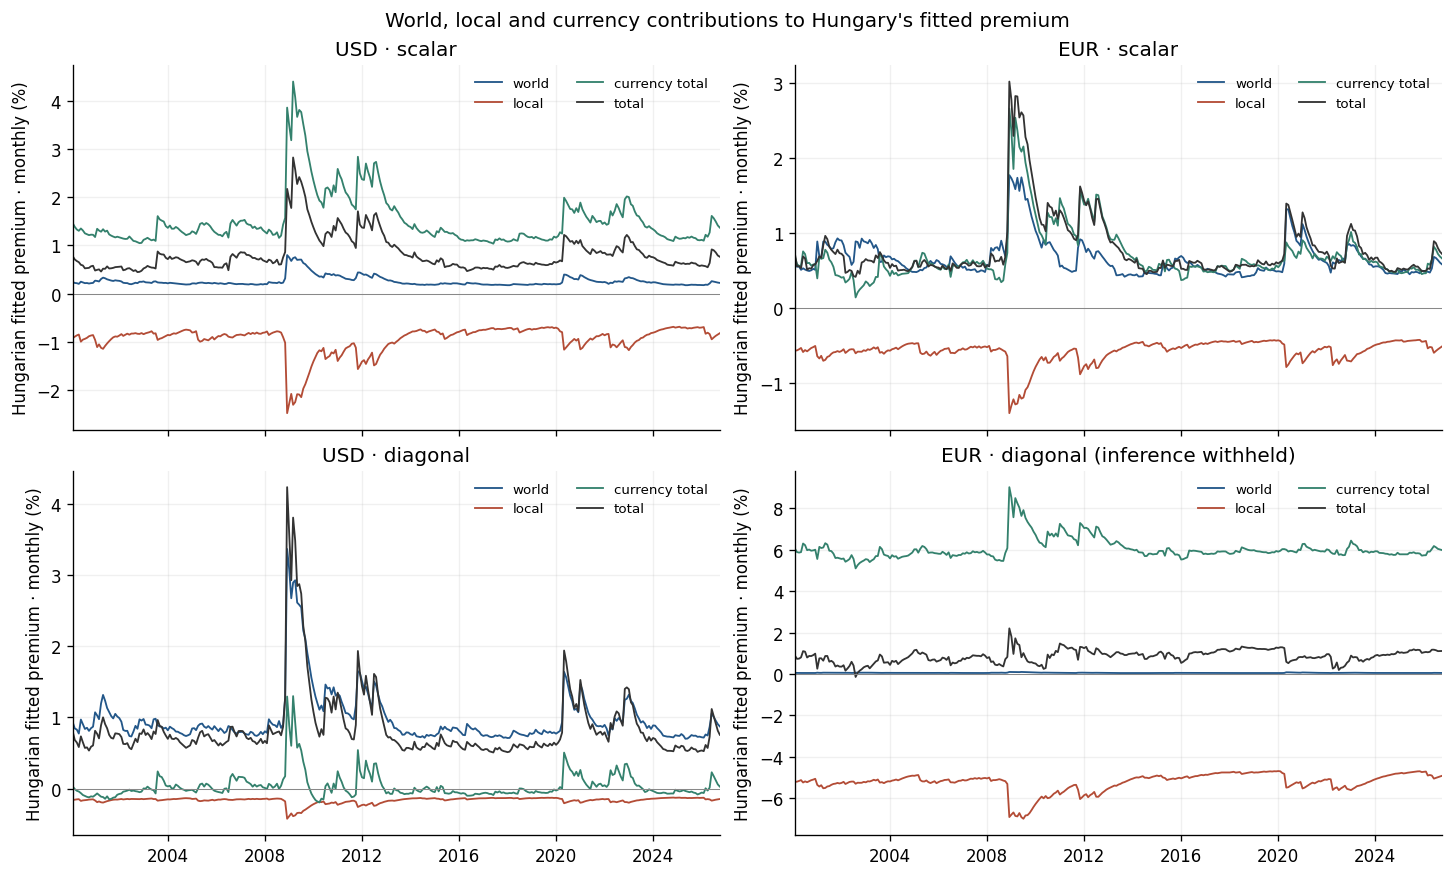

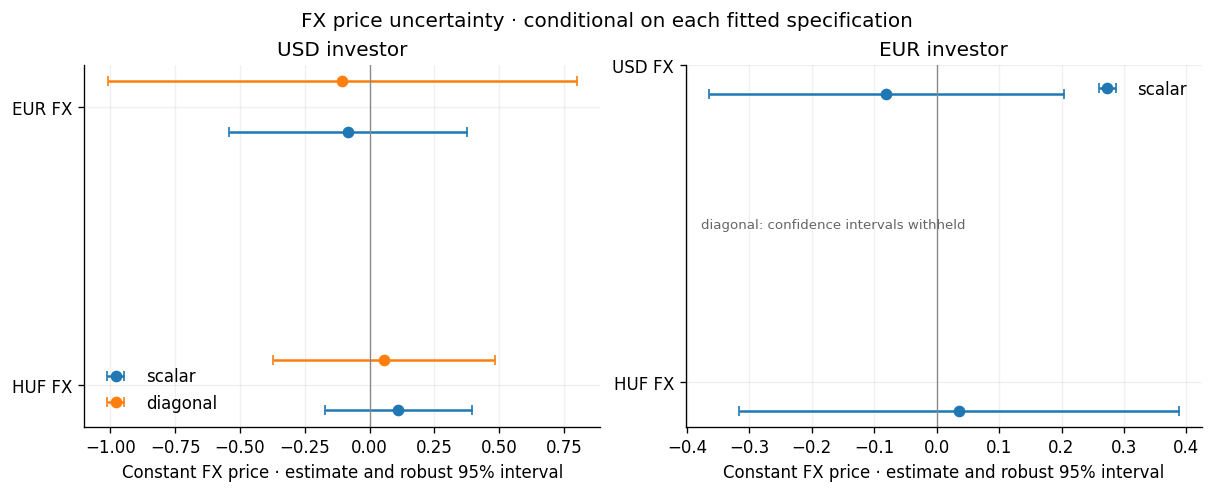

In [9]:
components={}
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3.6*len(COVARIANCE_MODELS)),
                      sharex=True,squeeze=False,layout="constrained")
dates=data.index.to_timestamp("M")
for row,covariance_model in enumerate(COVARIANCE_MODELS):
    for col,currency in enumerate(["USD","EUR"]):
        fit=fits[f"{currency}_{covariance_model}_with_fx"]
        f=fit["filter"]
        H,p=f["H"],f["prices"]
        frame=pd.DataFrame({"world":p[0]*H[:,2,0],"local":p[2]*H[:,2,2],
                            "HUF_FX":p[3]*H[:,2,3],"other_FX":p[4]*H[:,2,4]},index=data.index)
        frame["currency_total"]=frame["HUF_FX"]+frame["other_FX"]
        frame["total"]=frame["world"]+frame["local"]+frame["currency_total"]
        np.testing.assert_allclose(frame["total"],f["mu"][:,2],atol=1e-10,rtol=0)
        components[f"{currency}_{covariance_model}"]=frame
        ax=axes[row,col]
        for name,color in [("world","#235789"),("local","#b34c36"),("currency_total","#34816d"),("total","#333333")]:
            ax.plot(dates,frame[name],label=name.replace("_"," "),color=color,lw=1.1)
        ax.axhline(0,color="#888888",lw=.6)
        ax.set(title=f"{currency} · {covariance_model}"+(" (inference withheld)" if not fit["inference_ready"] else ""),ylabel="Hungarian fitted premium · monthly (%)",xlim=(dates[0],dates[-1]))
        ax.legend(frameon=False,ncol=2,fontsize=8)
fig.suptitle("World, local and currency contributions to Hungary's fitted premium")
plt.savefig(OUT/"01_hungary_premium_components.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

fig,axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
for ax,currency in zip(axes,["USD","EUR"]):
    for offset,covariance_model in enumerate(COVARIANCE_MODELS):
        risks=[f"{c} FX" for c in FX_NAMES[currency]]
        rows=price_table.loc[(currency,covariance_model,"with_fx")].loc[risks]
        position=np.arange(2)+(offset-(len(COVARIANCE_MODELS)-1)/2)*.18
        valid=rows["robust_se"].notna()
        if valid.any():
            ax.errorbar(rows.loc[valid,"estimate"],position[valid.to_numpy()],
                        xerr=1.96*rows.loc[valid,"robust_se"],fmt="o",capsize=3,label=covariance_model)
        if not valid.all():
            ax.text(.03,.5+offset*.05,f"{covariance_model}: confidence intervals withheld",
                    transform=ax.transAxes,fontsize=8,color="#666666")
    ax.axvline(0,color="#888888",lw=.8)
    ax.set(yticks=np.arange(2),yticklabels=[f"{c} FX" for c in FX_NAMES[currency]],
           title=f"{currency} investor",xlabel="Constant FX price · estimate and robust 95% interval")
    if ax.get_legend_handles_labels()[0]: ax.legend(frameon=False)
fig.suptitle("FX price uncertainty · conditional on each fitted specification")
plt.savefig(OUT/"02_currency_price_intervals.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 9. Final comparison and saved results

Read joint FX tests alongside the individual prices, confidence intervals, contribution magnitudes
and diagnostic flags. A failure to reject zero **constant** FX prices does not rule out time-varying
currency prices, and significance under one specification alone is weak evidence. The two FX prices
are coefficients on different factor bases across the two investor views.

`delta_AIC` and `delta_BIC` below are **with-FX minus no-FX**, within the same five-series model.
Negative values favour allowing currency prices. Diagnostic flags count nominal p < 0.05:
mean series, variance series (either squared-residual LB or ARCH), and whitened covariance pairs.

In [10]:
summary_rows,premium_rows=[],[]
for currency in ["USD","EUR"]:
    for covariance_model in COVARIANCE_MODELS:
        no=fit_table.loc[(currency,covariance_model,"no_fx")]
        yes=fit_table.loc[(currency,covariance_model,"with_fx")]
        prices=price_table.loc[(currency,covariance_model,"with_fx")]
        marginal=residual_table.loc[(currency,covariance_model,"with_fx")]
        cross=cross_table.loc[(currency,covariance_model,"with_fx")]
        summary_rows.append({"perspective":currency,"covariance_model":covariance_model,
            "FX_joint_p":wald_table.loc[(currency,covariance_model,"FX prices zero"),"robust_p_value"],
            "HUF_price":prices.loc["HUF FX","estimate"],"HUF_price_p":prices.loc["HUF FX","p_value"],
            "other_FX_price_p":prices.loc[f"{FX_NAMES[currency][1]} FX","p_value"],
            "local_joint_p":wald_table.loc[(currency,covariance_model,"Local prices zero"),"robust_p_value"],
            "delta_AIC":yes["AIC"]-no["AIC"],"delta_BIC":yes["BIC"]-no["BIC"],
            "mean_flags":int(marginal["LB_z_p"].lt(.05).sum()),
            "variance_flags":int((marginal["LB_z_squared_p"].lt(.05)|marginal["ARCH_LM_p"].lt(.05)).sum()),
            "cross_flags":int(cross["LB_product_p"].lt(.05).sum()),
            "inference_ready":bool(yes["numerical_inference_ready"])})
        for name,values in components[f"{currency}_{covariance_model}"].items():
            premium_rows.append({"perspective":currency,"covariance_model":covariance_model,"component":name,
                                 "mean_monthly_pct":values.mean(),"mean_annualised_log_pct":12*values.mean(),
                                 "sd_monthly_pct":values.std(ddof=1)})
summary=pd.DataFrame(summary_rows).set_index(["perspective","covariance_model"]).sort_index()
premium_table=pd.DataFrame(premium_rows).set_index(["perspective","covariance_model","component"]).sort_index()
tables={"fit_summary.csv":fit_table,"risk_prices.csv":price_table,"restriction_tests.csv":wald_table,
        "starting_points.csv":starts_table,"FX_VAR_coefficients.csv":var_table,"dynamics.csv":dynamics_table,
        "residual_diagnostics.csv":residual_table,"cross_covariance_diagnostics.csv":cross_table,
        "hungary_premium_summary.csv":premium_table,"summary.csv":summary}
for name,table in tables.items(): table.to_csv(OUT/name,float_format="%.17g",lineterminator="\n")
for key,fit in fits.items():
    np.savez(OUT/f"parameters_{key}.npz",theta=fit["theta"],robust_covariance=fit["covariance"],
             H=fit["filter"]["H"],mu=fit["filter"]["mu"],residuals=fit["filter"]["errors"])
for key,frame in components.items(): frame.to_csv(OUT/f"hungary_premium_{key.lower()}.csv",float_format="%.17g",lineterminator="\n")
record={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,"source_snapshot":SNAPSHOT,
        "source_dataset_sha256":manifest["exports"]["dataset.csv"],"raw_ecb_sha256":fx_source_sha256,
        "first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
        "series_order":ASSETS,"fx_names":FX_NAMES,"fx_convention":"foreign appreciation against investor currency",
        "equity_means":"constant world/local/FX covariance prices; two FX prices zero under no_fx",
        "FX_means":"unrestricted jointly estimated VAR; equity-pricing test only; no currency deposit pricing restriction",
        "FX_VAR_lags":FX_VAR_LAGS,"lag_choice":"exploratory after preliminary serial-dependence screening",
        "covariance_models":COVARIANCE_MODELS,"covariance":"free CC' intercept; stationary innovation H0; nonnegative diagonal A,B",
        "return_unit":"monthly log percentage points","test_lags":TEST_LAGS,"packages":versions,"python":platform.python_version()}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
for name,expected in [("dataset.csv",manifest["exports"]["dataset.csv"]),("raw/ecb_fx.csv",fx_source_sha256)]:
    if hashlib.sha256((source/name).read_bytes()).hexdigest()!=expected: raise ValueError("Frozen input changed.")
display(premium_table.loc[(slice(None),slice(None),["HUF_FX","other_FX","currency_total","total"]),:].round(4))
display(Markdown(f"**Final summary — {len(data)} matched months, FX VAR({FX_VAR_LAGS})**"))
display(summary.round(4))
for (currency,covariance_model),row in summary.iterrows():
    ptext=f"{row['FX_joint_p']:.3f}" if np.isfinite(row["FX_joint_p"]) else "withheld (numerical inference gate)"
    display(Markdown(f"**{currency} · {covariance_model}:** joint zero-FX-price p = **{ptext}**; "
        f"with-FX minus no-FX AIC = **{row['delta_AIC']:+.2f}**. "
        f"Residual flags: **{int(row['mean_flags'])} mean**, **{int(row['variance_flags'])} variance**, "
        f"**{int(row['cross_flags'])} covariance**. These exploratory checks limit structural conclusions."))
if "scalar" in COVARIANCE_MODELS:
    scalar_summary=summary.xs("scalar",level="covariance_model")
    if scalar_summary["FX_joint_p"].notna().all() and scalar_summary["FX_joint_p"].gt(.05).all():
        display(Markdown("**Main benchmark reading:** neither scalar system rejects zero constant FX prices. "
            "Individual intervals are wide, and residual variance/covariance flags remain. This leaves "
            "considerable uncertainty about currency-premium magnitudes and does not rule out time-varying prices."))
withheld=[f"{c} · {m}" for (c,m),r in summary.iterrows() if not r["inference_ready"]]
if withheld:
    display(Markdown("**Inference withheld:** "+", ".join(withheld)+
        ". Inspect the bound and curvature fields in `fit_summary.csv`; the associated component "
        "estimates are illustrative and do not support a currency-pricing conclusion."))
display(Markdown("This completes the constant-price currency extension in both investor currencies. "
    "Assess specification sensitivity before introducing time-varying risk prices; inflation instruments remain deferred. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. Frozen inputs are unchanged."))

mean_monthly_pct  \
perspective covariance_model component                          
EUR         diagonal         HUF_FX                    4.9530   
            scalar           HUF_FX                    0.3401   
USD         diagonal         HUF_FX                    1.2510   
            scalar           HUF_FX                    2.4557   
EUR         diagonal         other_FX                  1.0899   
            scalar           other_FX                  0.3645   
USD         diagonal         other_FX                 -1.2153   
            scalar           other_FX                 -0.9416   
EUR         diagonal         currency_total            6.0429   
            scalar           currency_total            0.7046   
USD         diagonal         currency_total            0.0357   
            scalar           currency_total            1.5141   
EUR         diagonal         total                     0.8591   
            scalar           total                     0.7736   
USD         diagonal         total                     0.8510   
            scalar           total                     0.8198   

                                             mean_annualised_log_pct  \
perspective covariance_model component                                 
EUR         diagonal         HUF_FX                          59.4355   
            scalar           HUF_FX                           4.0816   
USD         diagonal         HUF_FX                          15.0120   
            scalar           HUF_FX                          29.4681   
EUR         diagonal         other_FX                        13.0790   
            scalar           other_FX                         4.3737   
USD         diagonal         other_FX                       -14.5836   
            scalar           other_FX                       -11.2992   
EUR         diagonal         currency_total                  72.5144   
            scalar           currency_total                   8.4553   
USD         diagonal         currency_total                   0.4284   
            scalar           currency_total                  18.1689   
EUR         diagonal         total                           10.3094   
            scalar           total                            9.2829   
USD         diagonal         total                           10.2114   
            scalar           total                            9.8373   

                                             sd_monthly_pct  
perspective covariance_model component                       
EUR         diagonal         HUF_FX                  0.0059  
            scalar           HUF_FX                  0.1092  
USD         diagonal         HUF_FX                  0.4926  
            scalar           HUF_FX                  0.9440  
EUR         diagonal         other_FX                0.5110  
            scalar           other_FX                0.2774  
USD         diagonal         other_FX                0.3561  
            scalar           other_FX                0.4063  
EUR         diagonal         currency_total          0.5157  
            scalar           currency_total          0.3741  
USD         diagonal         currency_total          0.1802  
            scalar           currency_total          0.5526  
EUR         diagonal         total                   0.3045  
            scalar           total                   0.4263  
USD         diagonal         total                   0.4947  
            scalar           total                   0.3765

**Final summary — 321 matched months, FX VAR(6)**

FX_joint_p  HUF_price  HUF_price_p  \
perspective covariance_model                                       
EUR         diagonal                 NaN     0.4866          NaN   
            scalar                0.7693     0.0354       0.8439   
USD         diagonal              0.9681     0.0555       0.7990   
            scalar                0.6183     0.1102       0.4468   

                              other_FX_price_p  local_joint_p  delta_AIC  \
perspective covariance_model                                               
EUR         diagonal                       NaN            NaN    -2.2797   
            scalar                      0.5784         0.6261     3.1639   
USD         diagonal                    0.8193         0.9726     3.7427   
            scalar                      0.7270         0.4641     3.0247   

                              delta_BIC  mean_flags  variance_flags  \
perspective covariance_model                                          
EUR         diagonal             5.2632           1               2   
            scalar              10.7068           0               2   
USD         diagonal            11.2856           0               3   
            scalar              10.5676           0               4   

                              cross_flags  inference_ready  
perspective covariance_model                                
EUR         diagonal                    1            False  
            scalar                      1             True  
USD         diagonal                    1             True  
            scalar                      2             True

**EUR · diagonal:** joint zero-FX-price p = **withheld (numerical inference gate)**; with-FX minus no-FX AIC = **-2.28**. Residual flags: **1 mean**, **2 variance**, **1 covariance**. These exploratory checks limit structural conclusions.

**EUR · scalar:** joint zero-FX-price p = **0.769**; with-FX minus no-FX AIC = **+3.16**. Residual flags: **0 mean**, **2 variance**, **1 covariance**. These exploratory checks limit structural conclusions.

**USD · diagonal:** joint zero-FX-price p = **0.968**; with-FX minus no-FX AIC = **+3.74**. Residual flags: **0 mean**, **3 variance**, **1 covariance**. These exploratory checks limit structural conclusions.

**USD · scalar:** joint zero-FX-price p = **0.618**; with-FX minus no-FX AIC = **+3.02**. Residual flags: **0 mean**, **4 variance**, **2 covariance**. These exploratory checks limit structural conclusions.

**Main benchmark reading:** neither scalar system rejects zero constant FX prices. Individual intervals are wide, and residual variance/covariance flags remain. This leaves considerable uncertainty about currency-premium magnitudes and does not rule out time-varying prices.

**Inference withheld:** EUR · diagonal. Inspect the bound and curvature fields in `fit_summary.csv`; the associated component estimates are illustrative and do not support a currency-pricing conclusion.

This completes the constant-price currency extension in both investor currencies. Assess specification sensitivity before introducing time-varying risk prices; inflation instruments remain deferred. Outputs: `output/05_currency_risk/fixed_2026-11-13/2000-01_2026-09/var6`. Frozen inputs are unchanged.